# Ejercicio 5 — Poblaciones distintas con espectros casi indistinguibles

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from comun import cargar_datos

datos = cargar_datos()
lam, A, edades, b, b_ideal, x_real = (
    datos[k] for k in ("lam", "A", "edades", "b", "b_ideal", "x_real")
)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:.6g}".format)

e = b - b_ideal
eta = np.linalg.norm(e)
sigma = e.std()
n = A.shape[1]
uno = np.ones(n)

print("eta = ||b - b_ideal||_2 =", eta)

eta = ||b - b_ideal||_2 = 0.11465949557718051


## 1. Planteo

Se buscan dos composiciones $x^{(1)}, x^{(2)}$ en el conjunto de proporciones $\{x\in\mathbb{R}^{15}: x\ge0,\ \mathbf 1^\top x = 1\}$ que sean claramente distintas pero cuyos espectros cumplan $\|Ax^{(1)}-Ax^{(2)}\|_2<\eta$, con $\eta=\|b-b_{ideal}\|_2\approx0{,}115$ el nivel de ruido.

Siguiendo el tip, se parte de $x_0$ y se usan composiciones $x_0+\tau d$ con un **vector de redistribución** $d$, $\mathbf 1^\top d=0$:

- La suma se conserva para todo $\tau$: $\mathbf 1^\top(x_0+\tau d) = 1 + \tau\cdot0 = 1$. Solo hay que cuidar la **positividad**, que limita cuánto se puede avanzar sobre $d$.
- Si $x^{(1)} = x_0+\tau_+ d$ y $x^{(2)} = x_0-\tau_- d$, con $\tau_\pm\ge0$, entonces
$$x^{(1)}-x^{(2)} = (\tau_++\tau_-)\,d, \qquad b^{(1)}-b^{(2)} = (\tau_++\tau_-)\,Ad .$$
La diferencia en el espectro es proporcional a $\|Ad\|$. Para que las composiciones difieran mucho y los espectros poco, hace falta una **redistribución $d$ con $\|Ad\|$ lo más chico posible**:
$$\min_{\|d\|_2=1,\ \mathbf 1^\top d=0}\ \|Ad\|_2 .$$

Se toma $x_0 = x_{real}$, que es interior al conjunto (todas sus componentes son ≥ 0,03). Eso deja margen para moverse en ambos sentidos y permite leer el resultado como "la composición verdadera frente a alternativas".

## 2. Base ortonormal de las redistribuciones (QR)

El conjunto de redistribuciones permitidas $\{d: \mathbf 1^\top d = 0\} = \mathbf 1^\perp$ es un subespacio de dimensión 14. Para obtener una base ortonormal se calcula la **factorización QR completa** del vector $\mathbf 1\in\mathbb{R}^{15\times1}$:

$$\mathbf 1 = QR = \begin{bmatrix} q_1 & Q_2\end{bmatrix}\begin{bmatrix} r_{11}\\ 0\end{bmatrix}, \qquad Q\in\mathbb{R}^{15\times15}\ \text{ortogonal}.$$

- Como $\mathbf 1 = r_{11}q_1$, la primera columna es $q_1 = \mathbf 1/r_{11}$, con $|r_{11}| = \|\mathbf 1\|_2 = \sqrt{15}$. Se verifica $r_{11} = -\sqrt{15}$ y $q_1 = -\mathbf 1/\sqrt{15}$ (el signo depende de la convención de Householder).
- Las columnas de $Q_2\in\mathbb{R}^{15\times14}$ son ortonormales y ortogonales a $q_1$, es decir, a $\mathbf 1$: forman una **base ortonormal de $\mathbf 1^\perp$**. Se verifica que $Q^\top Q = I$ y $\mathbf 1^\top Q_2 = 0$ a precisión de máquina.

Toda redistribución se escribe entonces como $d = Q_2c$, con $c\in\mathbb{R}^{14}$, y $\|d\|_2 = \|c\|_2$ porque $Q_2$ tiene columnas ortonormales. La restricción $\mathbf 1^\top d=0$ desaparece al cambiar de variable.

In [2]:
Q, R = np.linalg.qr(uno.reshape(-1, 1), mode="complete")
q1 = Q[:, 0]
Q2 = Q[:, 1:]

print("Q.shape =", Q.shape)
print(f"R[0, 0] = {R[0, 0]:.6f} | ±sqrt(n) = ±{np.sqrt(n):.6f}")
print("||Q.T @ Q - I|| =", np.linalg.norm(Q.T @ Q - np.eye(n)))
print("max |uno.T @ Q2| =", np.abs(uno @ Q2).max())
print(f"q1[0] = {q1[0]:.6f} | ±1/sqrt(n) = ±{1 / np.sqrt(n):.6f} | max |q1 - q1[0]| = {np.abs(q1 - q1[0]).max():.3e}")

Q.shape = (15, 15)
R[0, 0] = -3.872983 | ±sqrt(n) = ±3.872983
||Q.T @ Q - I|| = 7.359125013523932e-16
max |uno.T @ Q2| = 3.3306690738754696e-16
q1[0] = -0.258199 | ±1/sqrt(n) = ±0.258199 | max |q1 - q1[0]| = 5.551e-17


## 3. Redistribuciones que menos modifican el espectro (SVD)

Con $d = Q_2c$, el problema queda **sin restricciones**:

$$\min_{\|c\|_2=1}\ \|AQ_2\,c\|_2 = \sigma_{min}(AQ_2),$$

y el mínimo se alcanza en $c = v_{14}$, el último vector singular derecho de $B = AQ_2\in\mathbb{R}^{4300\times14}$ (cociente de Rayleigh de $B^\top B$). Más en general, la SVD de $B$ **ordena las redistribuciones según cuánto modifican el espectro**: $d_i = Q_2v_i$ cambia el espectro en $\|Ad_i\| = \sigma_i(B)$.

**Resultados**
- $\sigma_i(AQ_2)$ va de 63,5 a **0,040**: la redistribución más "visible" cambia el espectro unas **1600 veces más** que la menos visible.
- $\sigma_{min}(AQ_2) = 0{,}0402$ es prácticamente igual a $\sigma_{15}(A) = 0{,}0398$. Restringir a $\mathbf 1^\perp$ no puede bajarlo ($\|AQ_2c\|\ge\sigma_{min}(A)\|c\|$), y en este caso tampoco lo sube: la dirección "mala" de $A$ ya es casi una redistribución.
- En cambio, $\sigma_1(A) = 241$ cae a $\sigma_1(AQ_2) = 63{,}5$. La dirección más visible de $A$ es esencialmente la del **total** ($\mathbf 1$), porque todas las columnas son parecidas y $Ax\approx(\sum_jx_j)\cdot$(espectro medio). Los datos determinan muy bien la suma, y mucho peor cómo se reparte.

**Estructura de $d$.** Casi todo su peso está en tres edades consecutivas: $-0{,}42$ en 2,8 Gyr, $+0{,}79$ en 4 Gyr y $-0{,}41$ en 5,6 Gyr, con componentes ≤ 0,12 en el resto. Es un patrón de **segunda diferencia** $(-1, 2, -1)$: agregar luz de 4 Gyr y sacar la mitad de esa cantidad de cada vecina. Como los espectros SSP varían suavemente con $\log t$, el espectro de 4 Gyr es casi el promedio de los de 2,8 y 5,6 Gyr ($\log$ equiespaciados), y esa redistribución casi no altera $Ax$. Es la **degeneración de edad** entre poblaciones viejas que ya sugerían las correlaciones ≈ 1 entre SSP viejas vecinas del Ej. 1.

In [3]:
B = A @ Q2
Ub, sb, Vbt = np.linalg.svd(B, full_matrices=False)

print("Valores singulares de B = A Q2:")
for i, sv in enumerate(sb, start=1):
    print(f"  σ_{i:2d} = {sv:.4e}")
print("sb[0] / sb[-1] =", sb[0] / sb[-1])

c = Vbt[-1]
d = Q2 @ c
if d[np.argmax(np.abs(d))] < 0:
    d = -d

print("uno.T @ d =", uno @ d)
print("||d||_2 =", np.linalg.norm(d))
print("||A d||_2 =", np.linalg.norm(A @ d), "| sb[-1] =", sb[-1])
print("contraste: ||A (Q2 Vbt[0])||_2 =", np.linalg.norm(A @ (Q2 @ Vbt[0])), "| sb[0] =", sb[0])

tabla_d = pd.DataFrame({"edad": edades, "d": d.round(3)})
tabla_d

Valores singulares de B = A Q2:
  σ_ 1 = 6.3493e+01
  σ_ 2 = 8.2560e+00
  σ_ 3 = 3.2317e+00
  σ_ 4 = 7.1051e-01
  σ_ 5 = 4.5449e-01
  σ_ 6 = 3.3687e-01
  σ_ 7 = 2.8565e-01
  σ_ 8 = 2.1785e-01
  σ_ 9 = 1.6588e-01
  σ_10 = 1.3379e-01
  σ_11 = 9.9775e-02
  σ_12 = 6.7948e-02
  σ_13 = 6.0027e-02
  σ_14 = 4.0230e-02
sb[0] / sb[-1] = 1578.268409627937
uno.T @ d = -5.551115123125783e-17
||d||_2 = 0.9999999999999998
||A d||_2 = 0.04022970007950078 | sb[-1] = 0.040229700079500504
contraste: ||A (Q2 Vbt[0])||_2 = 63.49326476428217 | sb[0] = 63.49326476428215


,edad,d
0,0.0631,0.045
1,0.0891,-0.067
2,0.1413,0.045
3,0.1995,-0.032
4,0.2818,-0.018
5,0.3981,0.05
6,0.631,-0.052
7,0.8913,0.067
8,1.2589,-0.069
9,1.9953,0.119


## 4. Construcción de $x^{(1)}$ y $x^{(2)}$

**Paso máximo.** Para cada sentido, el paso máximo que mantiene $x\ge0$ es

$$\tau_+ = \min_{j:\,d_j<0}\frac{x_{0,j}}{|d_j|} \approx 0{,}123, \qquad \tau_- = \min_{j:\,d_j>0}\frac{x_{0,j}}{d_j} \approx 0{,}076 .$$

Con esos valores, $x^{(1)}$ anula la población de 5,6 Gyr y $x^{(2)}$ la de 4 Gyr. Se toman $\tau_+$ y $\tau_-$ distintos, cada uno en su máximo, para que las dos distribuciones queden lo más separadas posible sobre $d$, y ambas quedan en el borde del conjunto factible.

**Cota por ruido.** La condición $\|b^{(1)}-b^{(2)}\| = (\tau_++\tau_-)\,\|Ad\| < \eta$ exige $\tau_++\tau_- < \eta/\|Ad\| \approx 2{,}85$, mientras que la positividad permite solo $\tau_++\tau_- \approx 0{,}20$. **La restricción activa es la positividad, no el ruido**, con un margen de ~14 veces. Sobre esta dirección $d$, lo único que impide alejarse más de $x_0$ es que las proporciones no pueden ser negativas.

**Resultado**

| | 2,8 Gyr | 4 Gyr | 5,6 Gyr |
|---|---|---|---|
| $x_0 = x_{real}$ | 0,080 | 0,060 | 0,050 |
| $x^{(1)}$ | 0,029 | **0,157** | **0** |
| $x^{(2)}$ | 0,112 | **0** | 0,081 |

- Ambas son proporciones válidas ($\sum = 1$, $\min = 0$).
- **Son claramente distintas:** $\|x^{(1)}-x^{(2)}\|_2/\|x_0\|_2 \approx 73\,\%$ y $\tfrac12\|x^{(1)}-x^{(2)}\|_1 \approx 0{,}22$, o sea que el **22 % de la luz** está asignado a edades diferentes. En una, la población de 4 Gyr aporta casi el 16 % de la luz; en la otra, nada.
- **Sus espectros son indistinguibles:** $\|b^{(1)}-b^{(2)}\|_2 \approx 0{,}008 = 0{,}07\,\eta$, una diferencia relativa de $1{,}3\times10^{-4}$. Píxel a píxel, la diferencia máxima es $0{,}41\,\sigma_{ruido}$.

In [4]:
x0 = x_real.copy()
# máximo paso admisible en cada sentido para que x0 + t d >= 0
tau_mas  = np.min(x0[d < 0] / -d[d < 0])   # x0 + tau d,  tau > 0
tau_menos = np.min(x0[d > 0] / d[d > 0])   # x0 - tau d,  tau > 0
tau_eta = eta / np.linalg.norm(A @ d)      # cota por ruido para ||A (x1 - x2)|| = (tau_mas+tau_menos)||Ad|| < eta

# índices que alcanzan el borde de positividad
idx_mas = np.flatnonzero(d < 0)
i_mas = idx_mas[np.argmin(x0[idx_mas] / -d[idx_mas])]
idx_menos = np.flatnonzero(d > 0)
i_menos = idx_menos[np.argmin(x0[idx_menos] / d[idx_menos])]

print(f"tau_mas = {tau_mas:.6g}")
print(f"tau_menos = {tau_menos:.6g}")
print(f"tau_mas + tau_menos = {tau_mas + tau_menos:.6g}")
print(f"tau_eta = {tau_eta:.6g}")
print("Restricción activa:", "positividad" if tau_mas + tau_menos < tau_eta else "ruido")
assert tau_mas + tau_menos < tau_eta

x1 = np.maximum(x0 + tau_mas * d, 0)
x2 = np.maximum(x0 - tau_menos * d, 0)
print(f"x1: la componente de edad {edades[i_mas]:g} Gyr llega a 0 (x1 = {x1[i_mas]:.3g})")
print(f"x2: la componente de edad {edades[i_menos]:g} Gyr llega a 0 (x2 = {x2[i_menos]:.3g})")

b1 = A @ x1
b2 = A @ x2
db = b1 - b2
dif = x1 - x2
j = np.argmax(np.abs(dif))
ratio = np.linalg.norm(db) / eta

print("sum x1 =", x1.sum(), "| sum x2 =", x2.sum())
print("min x1 =", x1.min(), "| min x2 =", x2.min())
print("||x1 - x2||_2 =", np.linalg.norm(dif))
print("||x1 - x2||_2 / ||x0||_2 =", np.linalg.norm(dif) / np.linalg.norm(x0))
print("||x1 - x2||_1 =", np.abs(dif).sum())
print(f"max |x1 - x2| = {np.abs(dif).max():.6g} en la edad {edades[j]:g} Gyr")
print("||b1 - b2||_2 =", np.linalg.norm(db))
print("||b1 - b2||_2 / eta =", ratio)
print(f"max |b1 - b2| = {np.abs(db).max():.6g} | sigma = std(e) = {sigma:.6g} | max|b1 - b2| / sigma = {np.abs(db).max() / sigma:.6g}")
print("||b1 - b2||_2 / ||b1||_2 =", np.linalg.norm(db) / np.linalg.norm(b1))

tabla_x = pd.DataFrame({"edad": edades, "x0": x0, "x1": x1, "x2": x2, "x1 − x2": dif})
tabla_x

tau_mas = 0.122597
tau_menos = 0.0761757
tau_mas + tau_menos = 0.198773
tau_eta = 2.85012
Restricción activa: positividad
x1: la componente de edad 5.6234 Gyr llega a 0 (x1 = 0)
x2: la componente de edad 3.9811 Gyr llega a 0 (x2 = 0)
sum x1 = 1.0 | sum x2 = 1.0
min x1 = 0.0 | min x2 = 0.0
||x1 - x2||_2 = 0.19877278465254433
||x1 - x2||_2 / ||x0||_2 = 0.7277588713160279
||x1 - x2||_1 = 0.4426576272288502
max |x1 - x2| = 0.156564 en la edad 3.9811 Gyr
||b1 - b2||_2 = 0.007996569510538865
||b1 - b2||_2 / eta = 0.06974188635912976
max |b1 - b2| = 0.000722855 | sigma = std(e) = 0.00174824 | max|b1 - b2| / sigma = 0.413477
||b1 - b2||_2 / ||b1||_2 = 0.00013102690208716036


,edad,x0,x1,x2,x1 − x2
0,0.0631,0.03,0.0355026,0.026581,0.00892158
1,0.0891,0.04,0.0318211,0.0450819,-0.0132608
2,0.1413,0.05,0.0555305,0.0465636,0.00896688
3,0.1995,0.06,0.0560783,0.0624368,-0.00635846
4,0.2818,0.07,0.0678509,0.0713354,-0.00348452
5,0.3981,0.08,0.0861708,0.0761658,0.010005
6,0.631,0.09,0.0836597,0.0939395,-0.0102798
7,0.8913,0.1,0.10821,0.0948986,0.0133115
8,1.2589,0.1,0.0915814,0.105231,-0.0136495
9,1.9953,0.1,0.114531,0.0909711,0.02356


## 5. Gráficos

- **Distribuciones:** las dos composiciones coinciden aproximadamente con $x_{real}$ en las edades jóvenes e intermedias y difieren mucho en 2,8, 4 y 5,6 Gyr, exactamente donde se concentra $d$ (panel inferior).
- **Espectros:** $b^{(1)}$ y $b^{(2)}$ se superponen por completo. En el panel inferior, la diferencia $b^{(1)}-b^{(2)}$ (rojo) es una curva suave de amplitud muy por debajo del ruido del espectro medido (gris). La diferencia entre los dos espectros, $0{,}07\,\eta$, es mucho menor que el nivel de ruido que el enunciado toma como criterio de indistinguibilidad.

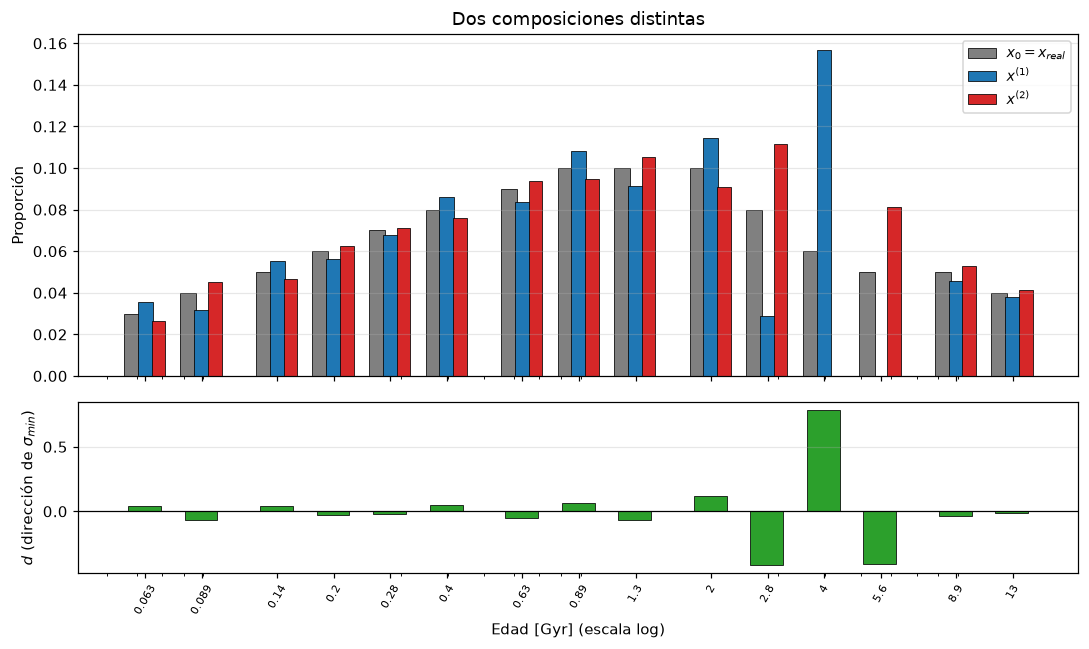

In [5]:
from matplotlib.ticker import NullFormatter

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.set_xscale("log")
ax1.bar(edades * 10 ** (-0.035), x_real, width=edades * 0.09, color="gray",
        edgecolor="k", linewidth=0.5, label=r"$x_0 = x_{real}$")
ax1.bar(edades, x1, width=edades * 0.09, color="C0", edgecolor="k",
        linewidth=0.5, label=r"$x^{(1)}$")
ax1.bar(edades * 10 ** (+0.035), x2, width=edades * 0.09, color="C3",
        edgecolor="k", linewidth=0.5, label=r"$x^{(2)}$")
ax1.set_ylabel("Proporción")
ax1.set_title("Dos composiciones distintas")
ax1.legend(loc="best", fontsize=9)

ax2.set_xscale("log")
ax2.bar(edades, d, width=edades * 0.2, color="C2", edgecolor="k", linewidth=0.5)
ax2.axhline(0, color="k", linewidth=0.8)
ax2.set_ylabel(r"$d$ (dirección de $\sigma_{min}$)")
ax2.set_xlabel("Edad [Gyr] (escala log)")

for ax in (ax1, ax2):
    ax.set_xticks(edades)
    ax.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=7)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(True, axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(FIG / "01_distribuciones.png")
plt.show()

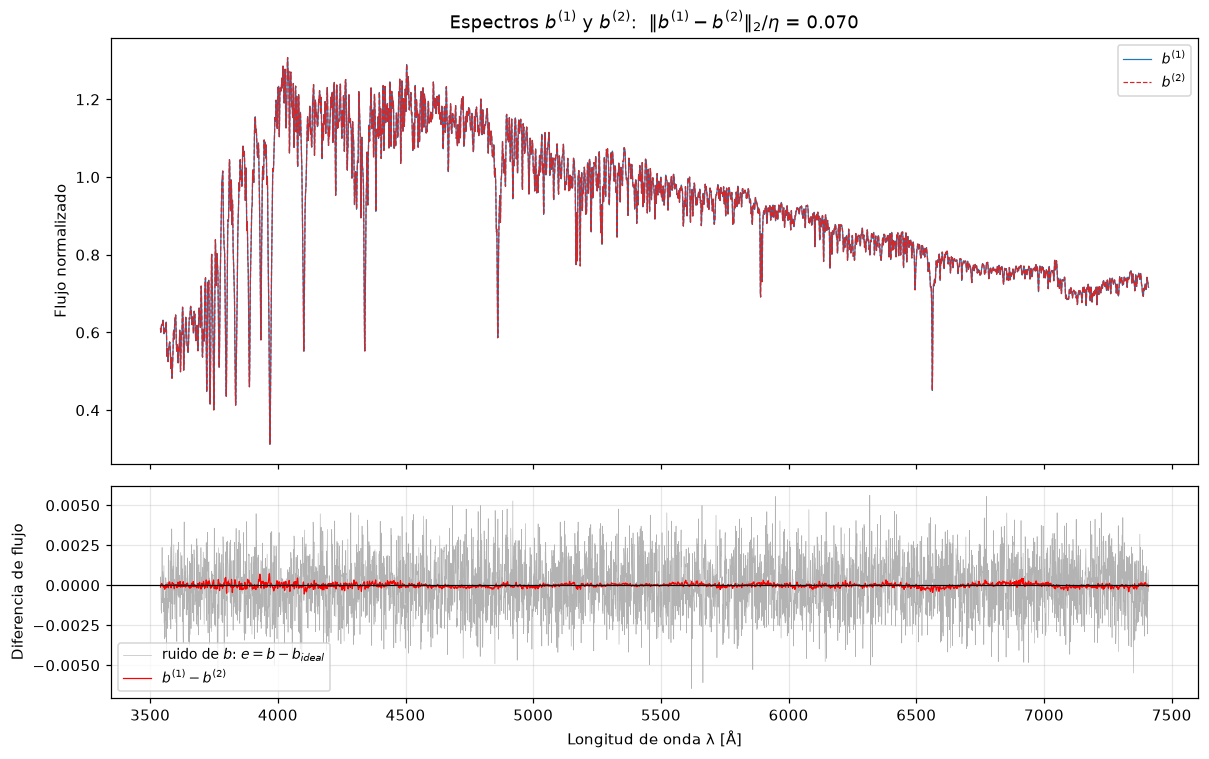

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(lam, b1, color="C0", lw=0.8, label=r"$b^{(1)}$")
ax1.plot(lam, b2, color="C3", lw=0.8, linestyle="--", label=r"$b^{(2)}$")
ax1.set_ylabel("Flujo normalizado")
ax1.set_title(rf"Espectros $b^{{(1)}}$ y $b^{{(2)}}$:  $\|b^{{(1)}}-b^{{(2)}}\|_2 / \eta$ = {ratio:.3f}")
ax1.legend(loc="best", fontsize=9)

ax2.plot(lam, e, color="0.7", lw=0.4, label=r"ruido de $b$: $e = b - b_{ideal}$")
ax2.plot(lam, db, color="red", lw=0.8, label=r"$b^{(1)} - b^{(2)}$")
ax2.axhline(0, color="k", linewidth=0.8)
ax2.set_xlabel("Longitud de onda λ [Å]")
ax2.set_ylabel("Diferencia de flujo")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best", fontsize=9)

fig.tight_layout()
fig.savefig(FIG / "02_espectros.png")
plt.show()

## Conclusiones del ejercicio 5

1. La QR completa de $\mathbf 1$ da una base ortonormal $Q_2$ de las redistribuciones ($\mathbf 1^\top d = 0$), y la SVD de $AQ_2$ las ordena según cuánto cambian el espectro. La menos visible tiene $\|Ad\| = \sigma_{min}(AQ_2) \approx 0{,}040$, unas 1600 veces menos que la más visible.
2. Esa redistribución es un patrón $(-1, 2, -1)$ sobre 2,8, 4 y 5,6 Gyr: el espectro de una población vieja es casi el promedio de los de sus vecinas en $\log t$.
3. Moviéndose sobre $d$ hasta el borde de $x\ge0$ se obtienen dos composiciones válidas que difieren en un 73 % (22 % de la luz reasignada) y cuyos espectros difieren en solo **0,07 $\eta$**. La restricción activa es la positividad: el ruido permitiría diferencias ~14 veces mayores.
4. **No es posible recuperar una única distribución de edades a partir de $b$ con este nivel de ruido.** Aunque $A$ tiene rango completo y la solución de cuadrados mínimos es matemáticamente única, hay todo un conjunto de composiciones físicamente válidas compatibles con los datos. Tomando cambios del tamaño de los encontrados acá ($\|\Delta x\|\approx0{,}2$), toda dirección con $\sigma_i(AQ_2) \lesssim \eta/0{,}2 \approx 0{,}57$ produce espectros indistinguibles: son 10 de las 14 redistribuciones posibles. El espectro determina con precisión solo unas pocas combinaciones (el total y la forma gruesa de la distribución, coherente con el codo en $\sigma_4$ del Ej. 3), no el aporte de cada edad por separado.
5. Por eso los métodos regularizados de los Ej. 3 y 4 no "descubren" la composición verdadera: eligen, entre todas las compatibles con los datos, la que satisface un criterio impuesto (menor norma, componentes truncadas). Su error en $x$ del ~6 % está justamente en estas direcciones no determinadas. Para afirmar algo sobre edades individuales hace falta información adicional (menos ruido, más rango espectral, o supuestos a priori como suavidad en edad), o bien reportar resultados agrupados en rangos de edad.